#activity 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

(x_train_full, y_train_full), (x_test_full, y_test_full) = (
    tf.keras.datasets.mnist.load_data()
)

def balanced_subset(images, labels, per_class, seed=SEED):
    rng = np.random.default_rng(seed)
    chosen = []
    for class_id in range(10):
        indices = np.where(labels == class_id)[0]
        chosen.extend(rng.choice(indices, size=per_class, replace=False))
    chosen = np.asarray(chosen)
    rng.shuffle(chosen)
    return images[chosen], labels[chosen]

# Same sample sizes as the previous lab: 100 training images per digit,
# and 20 test images per digit.
x_train_small, y_train_small = balanced_subset(
    x_train_full, y_train_full, per_class=100, seed=SEED
)

x_test_raw, y_test = balanced_subset(
    x_test_full, y_test_full, per_class=20, seed=SEED + 1
)

print("Selected training subset:", x_train_small.shape)
print("Selected test subset:", x_test_raw.shape)
print("Training examples per class:", np.bincount(y_train_small))
print("Test examples per class:", np.bincount(y_test))


TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Selected training subset: (1000, 28, 28)
Selected test subset: (200, 28, 28)
Training examples per class: [100 100 100 100 100 100 100 100 100 100]
Test examples per class: [20 20 20 20 20 20 20 20 20 20]


#activity 2

In [ ]:
# Split before preprocessing so validation images are not used to update model weights.
x_train_raw, x_val_raw, y_train, y_val = train_test_split(
    x_train_small,
    y_train_small,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_small
)

IMG_SIZE = 96

def prepare_for_densenet(images):
    # Input images: (N, 28, 28)
    # Add channel axis and repeat grayscale into 3 channels: (N, 28, 28, 3)
    images = images[..., np.newaxis]
    images = np.repeat(images, 3, axis=-1).astype("float32")

    # Resize to the input size used by this notebook.
    images = tf.image.resize(images, (IMG_SIZE, IMG_SIZE)).numpy()

    # Apply the preprocessing expected by DenseNet121 pretrained on ImageNet.
    # This is not the same as simply dividing by 255.
    images = tf.keras.applications.densenet.preprocess_input(images)
    return images.astype("float32")

x_train = prepare_for_densenet(x_train_raw)
x_val = prepare_for_densenet(x_val_raw)
x_test = prepare_for_densenet(x_test_raw)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Training tensor dtype:", x_train.dtype)


Training: (800, 96, 96, 3) (800,)
Validation: (200, 96, 96, 3) (200,)
Test: (200, 96, 96, 3) (200,)
Training tensor dtype: float32


#activity 3

In [ ]:
# Augmentation is applied only to training images.
# Inputs have already been resized and preprocessed for DenseNet121.
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,        # rotate by up to 10 degrees
    width_shift_range=0.08,   # shift horizontally by up to 8% of image width
    height_shift_range=0.08,  # shift vertically by up to 8% of image height
    zoom_range=0.10           # zoom in/out by up to approximately 10%
)

# No random transformations for validation or test data.
# These arrays are already preprocessed, so use them directly.
BATCH_SIZE = 32

train_generator = train_datagen.flow(
    x_train, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

print("Training batches per epoch:", len(train_generator))
print("Validation images (not augmented):", x_val.shape[0])
print("Test images (not augmented):", x_test.shape[0])


Training batches per epoch: 25
Validation images (not augmented): 200
Test images (not augmented): 200


#activity 4

In [ ]:
# Load the pretrained ImageNet backbone.
base_model = tf.keras.applications.DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

print("Backbone loaded.")
print("Backbone output shape:", base_model.output_shape)
print("Trainable backbone layers:", sum(layer.trainable for layer in base_model.layers))

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Extract features using the frozen pretrained DenseNet121.
features = base_model(inputs, training=False)
features = tf.keras.layers.GlobalAveragePooling2D()(features)
features = tf.keras.layers.Dropout(0.2)(features)

# New MNIST classification head: 10 output classes instead of 1,000.
outputs = tf.keras.layers.Dense(10, activation="softmax", name="mnist_predictions")(features)

model = tf.keras.Model(inputs, outputs, name="DenseNet121_MNIST")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("Trainable parameters:", sum(
    np.prod(v.shape) for v in model.trainable_variables
))


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Backbone loaded.
Backbone output shape: (None, 3, 3, 1024)
Trainable backbone layers: 0


Model: "DenseNet121_MNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 3, 3, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mnist_predictions (Dense)       │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,047,754 (26.89 MB)

 Trainable params: 10,250 (40.04 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Trainable parameters: 10250



#activity 5

mynotes: final de ga verbose pe

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint_path = "best_densenet121_mnist.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

history = model.fit(
    train_generator,
    validation_data=(x_val, y_val),
    epochs=15,
    callbacks=[early_stop, checkpoint]
)


Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.1553 - loss: 2.8652
Epoch 1: val_loss improved from None to 1.45644, saving model to best_densenet121_mnist.keras

Epoch 1: finished saving model to best_densenet121_mnist.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.2275 - loss: 2.4240 - val_accuracy: 0.4950 - val_loss: 1.4564
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.4058 - loss: 1.6895
Epoch 2: val_loss improved from 1.45644 to 0.99336, saving model to best_densenet121_mnist.keras

Epoch 2: finished saving model to best_densenet121_mnist.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 171ms/step - accuracy: 0.4963 - loss: 1.4964 - val_accuracy: 0.6700 - val_loss: 0.9934
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.6411 - loss: 1.0941
Epoch 3: val_loss improved from 0.99336 to 0.77257, saving model to best_densenet121_mnist.keras

Epoch 3: finished saving model to best_densenet121_mnist.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 167

#activity 6

In [ ]:
best_model = tf.keras.models.load_model(checkpoint_path)
test_loss, test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.3f} ({test_accuracy * 100:.1f}%)")


Test loss: 0.3543
Test accuracy: 0.910 (91.0%)


#activity 7

              precision    recall  f1-score   support

           0       0.94      0.85      0.89        20
           1       1.00      1.00      1.00        20
           2       0.94      0.85      0.89        20
           3       0.90      0.90      0.90        20
           4       0.94      0.85      0.89        20
           5       0.90      0.95      0.93        20
           6       0.87      1.00      0.93        20
           7       0.83      0.95      0.88        20
           8       0.90      0.90      0.90        20
           9       0.89      0.85      0.87        20

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.91       200
weighted avg       0.91      0.91      0.91       200



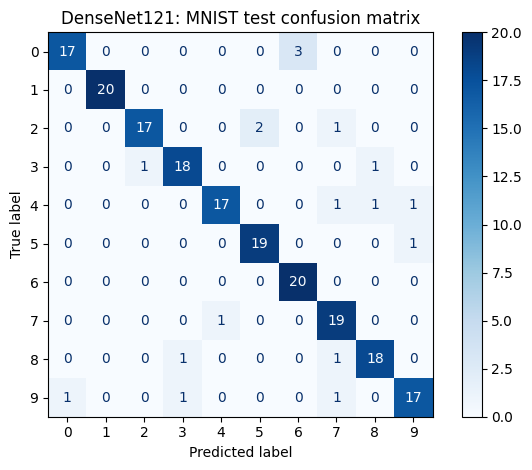

In [ ]:
probabilities = best_model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_test, y_pred,
    labels=list(range(10)),
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
disp.plot(cmap="Blues", values_format="d")

plt.title("DenseNet121: MNIST test confusion matrix")
plt.tight_layout()
plt.show()


#activity 8

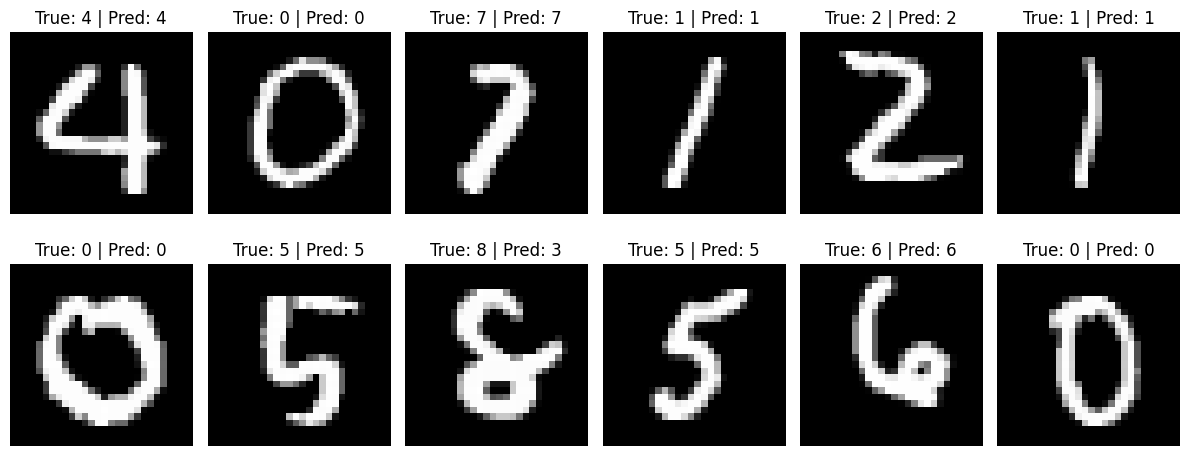

In [ ]:
# Display 12 test images using the best transfer-learning checkpoint (best_model).
transfer_probabilities = best_model.predict(x_test, verbose=0)

# selecting the class with highest probability
transfer_predictions = np.argmax(transfer_probabilities, axis=1)

# Select the indices of the first 12 test images
indices = np.arange(min(12, len(y_test)))

# Create a figure with 2 rows and 6 columns to display the test images
fig, axes = plt.subplots(2, 6, figsize=(12, 5))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(x_test_raw[idx], cmap="gray")
    ax.set_title(f"True: {y_test[idx]} | Pred: {transfer_predictions[idx]}")
    ax.axis("off")

plt.tight_layout()


#activity 9

In [ ]:
# Start from the best model saved during transfer learning.
fine_tune_model = tf.keras.models.load_model(checkpoint_path)

# Get the DenseNet121 backbone nested inside the full model.
backbone = fine_tune_model.get_layer("densenet121")

# First allow the backbone to be trainable, then freeze all but its final 20 layers.
backbone.trainable = True
for layer in backbone.layers[:-20]:
    layer.trainable = False

# Batch Normalization layers are kept frozen to avoid unstable batch statistics
# when training with a small MNIST subset.
# BatchNorm layer that normalizes the activations (outputs) of a previous layer so that their values
# remain within a more stable range during training.
for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Backbone layers:", len(backbone.layers))
print("Trainable backbone layers:", sum(layer.trainable for layer in backbone.layers))
print("Trainable parameter count:", sum(np.prod(v.shape) for v in fine_tune_model.trainable_variables))

# Recompile after changing trainable flags. Use a small learning rate so that
# pretrained features are adjusted gently rather than overwritten rapidly.
fine_tune_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_checkpoint_path = "best_densenet121_mnist_finetuned.keras"
fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=fine_tune_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

fine_tune_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

fine_tune_history = fine_tune_model.fit(
    train_generator,
    validation_data=(x_val, y_val),
    epochs=8,
    callbacks=[fine_tune_checkpoint, fine_tune_early_stop],
    verbose=1
)

print("Best fine-tuned checkpoint saved to:", fine_tune_checkpoint_path)


Backbone layers: 427
Trainable backbone layers: 14
Trainable parameter count: 370698
Epoch 1/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.8761 - loss: 0.3838
Epoch 1: val_loss improved from None to 0.36290, saving model to best_densenet121_mnist_finetuned.keras

Epoch 1: finished saving model to best_densenet121_mnist_finetuned.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.8788 - loss: 0.3771 - val_accuracy: 0.9150 - val_loss: 0.3629
Epoch 2/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9201 - loss: 0.3311
Epoch 2: val_loss improved from 0.36290 to 0.35689, saving model to best_densenet121_mnist_finetuned.keras

Epoch 2: finished saving model to best_densenet121_mnist_finetuned.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - accuracy: 0.9025 - loss: 0.3671 - val_accuracy: 0.9200 - val_loss: 0.3569
Epoch 3/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8807 - loss: 0.3493
Epoch 3: val_loss improved from 0.35689 to 0.35548, saving model to best

#final

In [ ]:
best_model2 = tf.keras.models.load_model(fine_tune_checkpoint_path)
test_loss, test_accuracy = best_model2.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.3f} ({test_accuracy * 100:.1f}%)")


Test loss: 0.3163
Test accuracy: 0.915 (91.5%)


              precision    recall  f1-score   support

           0       0.95      0.90      0.92        20
           1       1.00      1.00      1.00        20
           2       0.94      0.85      0.89        20
           3       0.90      0.90      0.90        20
           4       0.86      0.90      0.88        20
           5       0.90      0.95      0.93        20
           6       0.91      1.00      0.95        20
           7       0.86      0.90      0.88        20
           8       0.95      0.90      0.92        20
           9       0.89      0.85      0.87        20

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.91       200
weighted avg       0.92      0.92      0.91       200



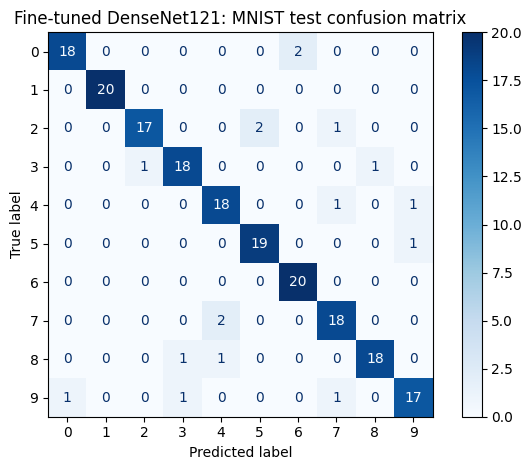

In [ ]:
fine_tuned_model = tf.keras.models.load_model(fine_tune_checkpoint_path)
fine_tuned_probabilities = fine_tuned_model.predict(x_test, verbose=0)
fine_tuned_predictions = np.argmax(fine_tuned_probabilities, axis=1)

print(classification_report(
    y_test, fine_tuned_predictions,
    labels=list(range(10)),
    zero_division=0
))

cm_finetuned = confusion_matrix(
    y_test, fine_tuned_predictions, labels=list(range(10))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_finetuned, display_labels=list(range(10))
)
disp.plot(cmap="Blues", values_format="d")

plt.title("Fine-tuned DenseNet121: MNIST test confusion matrix")
plt.tight_layout()
plt.show()


# Task


| Architecture | Selected variant | Purpose |
| :--- | :--- | :--- |
| **VGG** | VGG16 | Deep convolutional feature extraction |
| **ResNet** | ResNet50 | Residual learning |
| **MobileNet** | MobileNetV2 | Lightweight image classification |
| **DenseNet** | DenseNet121 | Dense feature connections |


Activity 1 – Import libraries and load dataset

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

# Load CIFAR-10 dataset
(x_train_full, y_train_full), (x_test_full, y_test_full) = (
    tf.keras.datasets.cifar10.load_data()
)

# Convert labels from (N, 1) to (N,)
y_train_full = y_train_full.flatten()
y_test_full = y_test_full.flatten()

# CIFAR-10 class names
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

# Select a balanced subset
def balanced_subset(images, labels, per_class, seed=SEED):
    rng = np.random.default_rng(seed)
    chosen = []

    for class_id in range(10):
        indices = np.where(labels == class_id)[0]
        chosen.extend(
            rng.choice(indices, size=per_class, replace=False)
        )

    chosen = np.asarray(chosen)
    rng.shuffle(chosen)

    return images[chosen], labels[chosen]


# 100 training images per class
x_train_small, y_train_small = balanced_subset(
    x_train_full, y_train_full,
    per_class=100,
    seed=SEED
)

# 20 test images per class
x_test_raw, y_test = balanced_subset(
    x_test_full, y_test_full,
    per_class=20,
    seed=SEED + 1
)

print("Training subset:", x_train_small.shape)
print("Testing subset:", x_test_raw.shape)

print("Training examples per class:",
      np.bincount(y_train_small))

print("Testing examples per class:",
      np.bincount(y_test))

TensorFlow version: 2.21.0
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 36s 0us/step
Training subset: (1000, 32, 32, 3)
Testing subset: (200, 32, 32, 3)
Training examples per class: [100 100 100 100 100 100 100 100 100 100]
Testing examples per class: [20 20 20 20 20 20 20 20 20 20]


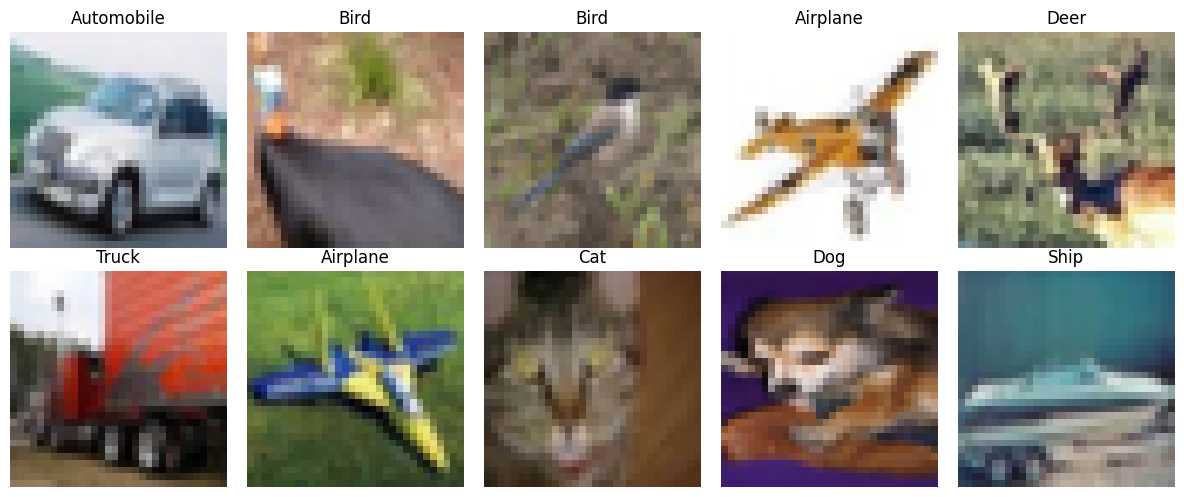

In [ ]:
# Display sample images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_small[i])
    plt.title(class_names[y_train_small[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

###my notes:
* Imports TensorFlow, NumPy, Matplotlib and evaluation tools.
* Loads the CIFAR-10 dataset.
* Selects 100 training images and 20 test images per class.
* Creates a balanced dataset of 10 classes.
* Displays sample CIFAR-10 images.

Activity 2 – Split and preprocess dataset

In [ ]:
# Split before preprocessing so validation images
# are not used to update model weights.

x_train_raw, x_val_raw, y_train, y_val = train_test_split(
    x_train_small,
    y_train_small,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_small
)

print("Training images:", x_train_raw.shape)
print("Validation images:", x_val_raw.shape)
print("Test images:", x_test_raw.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

print("Training examples per class:", np.bincount(y_train))
print("Validation examples per class:", np.bincount(y_val))

Training images: (800, 32, 32, 3)
Validation images: (200, 32, 32, 3)
Test images: (200, 32, 32, 3)
Training labels: (800,)
Validation labels: (200,)
Test labels: (200,)
Training examples per class: [80 80 80 80 80 80 80 80 80 80]
Validation examples per class: [20 20 20 20 20 20 20 20 20 20]


* Splits the training dataset into 80% training and 20% validation.
* Uses stratified splitting to maintain class balance.
* Keeps test images separate for final evaluation.
* Prevents validation images from being used for training.

Activity 3 – preprocess images for CNN architectures

In [ ]:
IMG_SIZE = 96

# Each architecture has its own preprocessing function.
preprocessing_functions = {
    "VGG16": tf.keras.applications.vgg16.preprocess_input,

    "ResNet50": tf.keras.applications.resnet50.preprocess_input,

    "MobileNetV2": tf.keras.applications.mobilenet_v2.preprocess_input,

    "DenseNet121": tf.keras.applications.densenet.preprocess_input
}


def prepare_images(images, architecture):

    # CIFAR-10 already contains RGB images.
    images = images.astype("float32")

    # Resize images from 32x32 to 96x96.
    images = tf.image.resize(
        images,
        (IMG_SIZE, IMG_SIZE)
    ).numpy()

    # Apply preprocessing required by the selected CNN.
    preprocess = preprocessing_functions[architecture]

    images = preprocess(images)

    return images.astype("float32")


print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Selected architectures:", list(preprocessing_functions.keys()))

# Test preprocessing with VGG16
sample_images = prepare_images(x_train_raw[:5], "VGG16")

print("Original image shape:", x_train_raw[:5].shape)
print("Processed image shape:", sample_images.shape)
print("Processed dtype:", sample_images.dtype)

Image size: 96 x 96
Selected architectures: ['VGG16', 'ResNet50', 'MobileNetV2', 'DenseNet121']
Original image shape: (5, 32, 32, 3)
Processed image shape: (5, 96, 96, 3)
Processed dtype: float32


###my notes:
* CIFAR-10 images are originally 32 × 32 RGB.
* Applies architecture-specific preprocessing.
* VGG16, ResNet50, MobileNetV2 and DenseNet121 each have their own preprocessing function.
* Produces images with three color channels.

Activity 4 – Apply image data augmentation

In [ ]:
# Augmentation is applied only to training images.

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True
)

# No random transformations for validation and test data.

BATCH_SIZE = 32


def create_train_generator(x_train, y_train):

    train_generator = train_datagen.flow(
        x_train,
        y_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED
    )

    return train_generator


print("Augmentation settings:")
print("Rotation: 10 degrees")
print("Width shift: 8%")
print("Height shift: 8%")
print("Zoom: 10%")
print("Horizontal flip: Enabled")
print("Batch size:", BATCH_SIZE)

Augmentation settings:
Rotation: 10 degrees
Width shift: 8%
Height shift: 8%
Zoom: 10%
Horizontal flip: Enabled
Batch size: 32


###my notes:
* Rotation changes image angles.
* Width and height shifts move images.
* Zoom changes image size.
* Horizontal flip creates mirrored images.
* Augmentation is applied only to training images, not validation or test images.

Activity 5 – Load and build four pretrained CNN architectures

In [ ]:
# Define the four selected pretrained architectures.

architecture_names = [
    "VGG16",
    "ResNet50",
    "MobileNetV2",
    "DenseNet121"
]

# Define the backbone models.
def load_backbone(architecture):

    if architecture == "VGG16":

        base_model = tf.keras.applications.VGG16(
            weights="imagenet",
            include_top=False,
            input_shape=(IMG_SIZE, IMG_SIZE, 3)
        )

    elif architecture == "ResNet50":

        base_model = tf.keras.applications.ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(IMG_SIZE, IMG_SIZE, 3)
        )

    elif architecture == "MobileNetV2":

        base_model = tf.keras.applications.MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(IMG_SIZE, IMG_SIZE, 3)
        )

    elif architecture == "DenseNet121":

        base_model = tf.keras.applications.DenseNet121(
            weights="imagenet",
            include_top=False,
            input_shape=(IMG_SIZE, IMG_SIZE, 3)
        )

    base_model.trainable = False

    return base_model


# Build the complete classification model.
def build_model(architecture):

    base_model = load_backbone(architecture)

    inputs = tf.keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # Extract features using frozen pretrained backbone.
    features = base_model(inputs, training=False)

    features = tf.keras.layers.GlobalAveragePooling2D()(features)

    features = tf.keras.layers.Dropout(0.2)(features)

    # CIFAR-10 has 10 output classes.
    outputs = tf.keras.layers.Dense(
        10,
        activation="softmax",
        name="cifar10_predictions"
    )(features)

    model = tf.keras.Model(
        inputs,
        outputs,
        name=architecture + "_CIFAR10"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("Selected architectures:", architecture_names)
print("Number of output classes: 10")

Selected architectures: ['VGG16', 'ResNet50', 'MobileNetV2', 'DenseNet121']
Number of output classes: 10


###my notes:
* Loads four pretrained ImageNet CNN models.
* Uses include_top=False to remove the original 1,000-class classification head.
* Freezes pretrained backbone layers.
* Adds Global Average Pooling and Dropout.
* Adds a new Dense layer with 10 softmax outputs for CIFAR-10.
* Uses Adam optimizer and categorical classification loss in sparse-label format.

Activity 6 – Train models using transfer learning

In [ ]:
# Store training histories and checkpoint paths.
histories = {}
checkpoint_paths = {}

for architecture in architecture_names:

    print("\n" + "=" * 60)
    print("Training:", architecture)
    print("=" * 60)

    tf.keras.backend.clear_session()

    # Prepare data for the current architecture.
    x_train = prepare_images(x_train_raw, architecture)
    x_val = prepare_images(x_val_raw, architecture)

    # Create augmented training generator.
    train_generator = create_train_generator(
        x_train,
        y_train
    )

    # Build the model.
    model = build_model(architecture)

    model.summary()

    # Adaptive learning rate.
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )

    # Stop training when validation loss stops improving.
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    # Save the best model.
    checkpoint_path = "best_" + architecture.lower() + "_cifar10.keras"

    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    )

    history = model.fit(
        train_generator,
        validation_data=(x_val, y_val),
        epochs=8,
        callbacks=[
            reduce_lr,
            early_stop,
            checkpoint
        ],
        verbose=1
    )

    histories[architecture] = history.history
    checkpoint_paths[architecture] = checkpoint_path

    print("Best checkpoint saved:", checkpoint_path)

    del model, train_generator, x_train, x_val
    tf.keras.backend.clear_session()


Training: VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cifar10_predictions (Dense)     │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,719,818 (56.15 MB)

 Trainable params: 5,130 (20.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

... (15 outputs left out)

 Total params: 7,047,754 (26.89 MB)

 Trainable params: 10,250 (40.04 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.1416 - loss: 3.9831
Epoch 1: val_loss improved from None to 1.93320, saving model to best_densenet121_cifar10.keras

Epoch 1: finished saving model to best_densenet121_cifar10.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.1800 - loss: 3.5734 - val_accuracy: 0.3550 - val_loss: 1.9332 - learning_rate: 0.0010
Epoch 2/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.3821 - loss: 2.1544
Epoch 2: val_loss improved from 1.93320 to 1.18161, saving model to best_densenet121_cifar10.keras

Epoch 2: finished saving model to best_densenet121_cifar10.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - accuracy: 0.4263 - loss: 1.8970 - val_accuracy: 0.6250 - val_loss: 1.1816 - learning_rate: 0.0010
Epoch 3/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5481 - loss: 1.5227
Epoch 3: val_loss improved from 1.18161 to 0.92859, saving model to best_densenet121_cifar10.keras

Epoch 3: finished saving model to best_de

###my notes:
* Trains VGG16, ResNet50, MobileNetV2 and DenseNet121 separately.
* Uses pretrained feature extraction.
* Applies augmented training images.
* Uses ReduceLROnPlateau for adaptive learning rate.
* Uses EarlyStopping to prevent unnecessary training.
* Uses ModelCheckpoint to save the best model.
* Maximum training epochs: 15 per architecture.

Activity 7 – Evaluate the four original models

In [ ]:
baseline_results = {}

for architecture in architecture_names:

    print("\nEvaluating:", architecture)

    # Load the best saved model.
    best_model = tf.keras.models.load_model(
        checkpoint_paths[architecture]
    )

    # Prepare test images.
    x_test = prepare_images(
        x_test_raw,
        architecture
    )

    # Evaluate the model.
    test_loss, test_accuracy = best_model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    baseline_results[architecture] = {
        "loss": test_loss,
        "accuracy": test_accuracy
    }

    print("Test loss:", round(test_loss, 4))
    print(
        "Test accuracy:",
        f"{test_accuracy:.3f} ({test_accuracy * 100:.2f}%)"
    )

    del best_model, x_test
    tf.keras.backend.clear_session()


Evaluating: VGG16
Test loss: 2.3756
Test accuracy: 0.570 (57.00%)

Evaluating: ResNet50
Test loss: 0.7986
Test accuracy: 0.765 (76.50%)

Evaluating: MobileNetV2
Test loss: 0.6865
Test accuracy: 0.760 (76.00%)

Evaluating: DenseNet121
Test loss: 0.7576
Test accuracy: 0.740 (74.00%)


###my notes:
* Loads each architecture's best checkpoint.
* Evaluates it on the separate CIFAR-10 test dataset.
* Calculates test loss and test accuracy.
* Stores results for comparison after fine-tuning.

Activity 8 – Classification report and confusion matrices


Classification Report: VGG16
              precision    recall  f1-score   support

    Airplane       0.65      0.65      0.65        20
  Automobile       0.62      0.65      0.63        20
        Bird       0.48      0.50      0.49        20
         Cat       0.56      0.45      0.50        20
        Deer       0.50      0.60      0.55        20
         Dog       0.40      0.40      0.40        20
        Frog       0.59      0.50      0.54        20
       Horse       0.59      0.65      0.62        20
        Ship       0.70      0.70      0.70        20
       Truck       0.63      0.60      0.62        20

    accuracy                           0.57       200
   macro avg       0.57      0.57      0.57       200
weighted avg       0.57      0.57      0.57       200



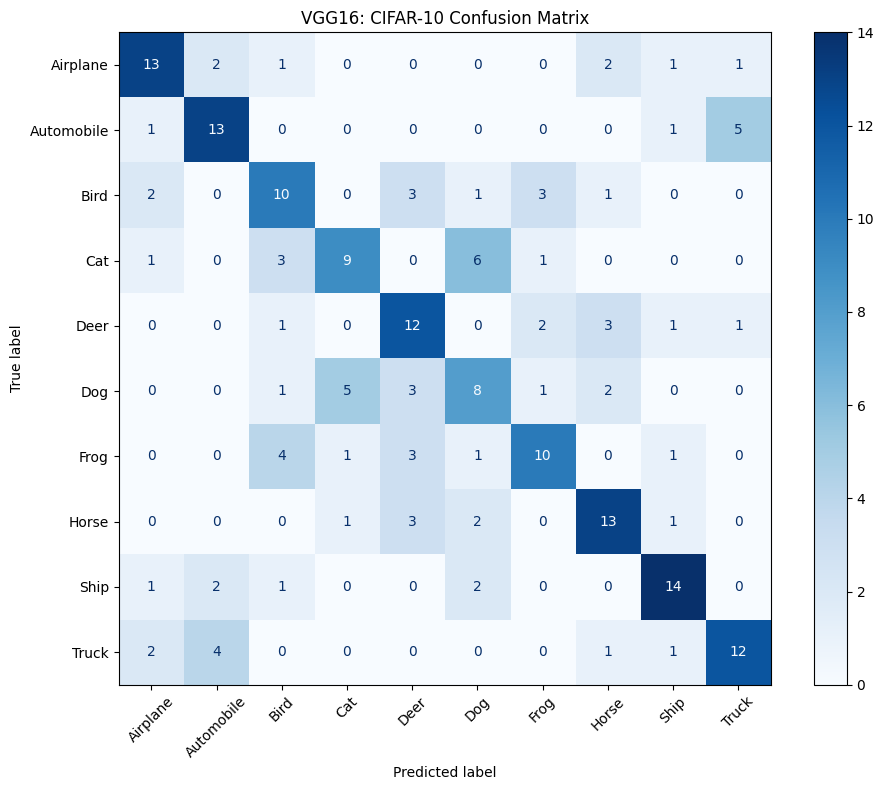


Classification Report: ResNet50


              precision    recall  f1-score   support

    Airplane       0.76      0.80      0.78        20
  Automobile       0.89      0.85      0.87        20
        Bird       0.72      0.65      0.68        20
         Cat       0.81      0.65      0.72        20
        Deer       0.70      0.70      0.70        20
         Dog       0.52      0.65      0.58        20
        Frog       0.90      0.95      0.93        20
       Horse       0.71      0.60      0.65        20
        Ship       0.81      0.85      0.83        20
       Truck       0.86      0.95      0.90        20

    accuracy                           0.77       200
   macro avg       0.77      0.76      0.76       200
weighted avg       0.77      0.77      0.76       200



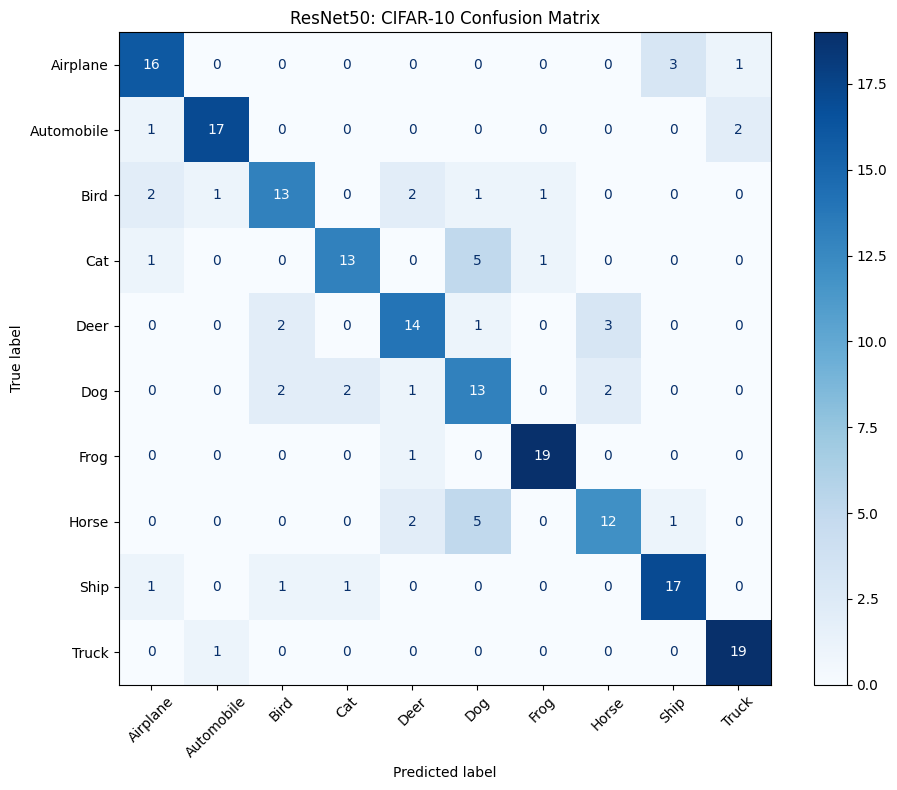


Classification Report: MobileNetV2


              precision    recall  f1-score   support

    Airplane       0.71      0.75      0.73        20
  Automobile       0.89      0.85      0.87        20
        Bird       0.67      0.80      0.73        20
         Cat       0.60      0.45      0.51        20
        Deer       1.00      0.60      0.75        20
         Dog       0.61      0.70      0.65        20
        Frog       0.86      0.90      0.88        20
       Horse       0.76      0.80      0.78        20
        Ship       0.77      0.85      0.81        20
       Truck       0.82      0.90      0.86        20

    accuracy                           0.76       200
   macro avg       0.77      0.76      0.76       200
weighted avg       0.77      0.76      0.76       200



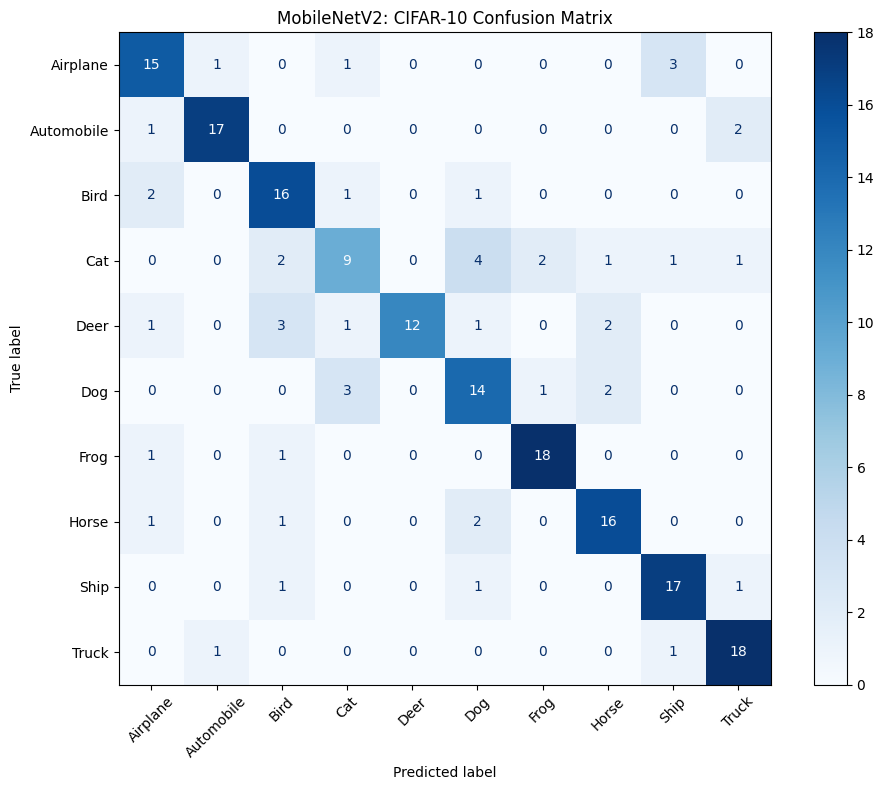


Classification Report: DenseNet121
              precision    recall  f1-score   support

    Airplane       0.71      0.85      0.77        20
  Automobile       0.75      0.75      0.75        20
        Bird       0.81      0.65      0.72        20
         Cat       0.65      0.55      0.59        20
        Deer       0.65      0.85      0.74        20
         Dog       0.76      0.65      0.70        20
        Frog       0.82      0.90      0.86        20
       Horse       0.79      0.55      0.65        20
        Ship       0.81      0.85      0.83        20
       Truck       0.70      0.80      0.74        20

    accuracy                           0.74       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.74      0.74      0.74       200



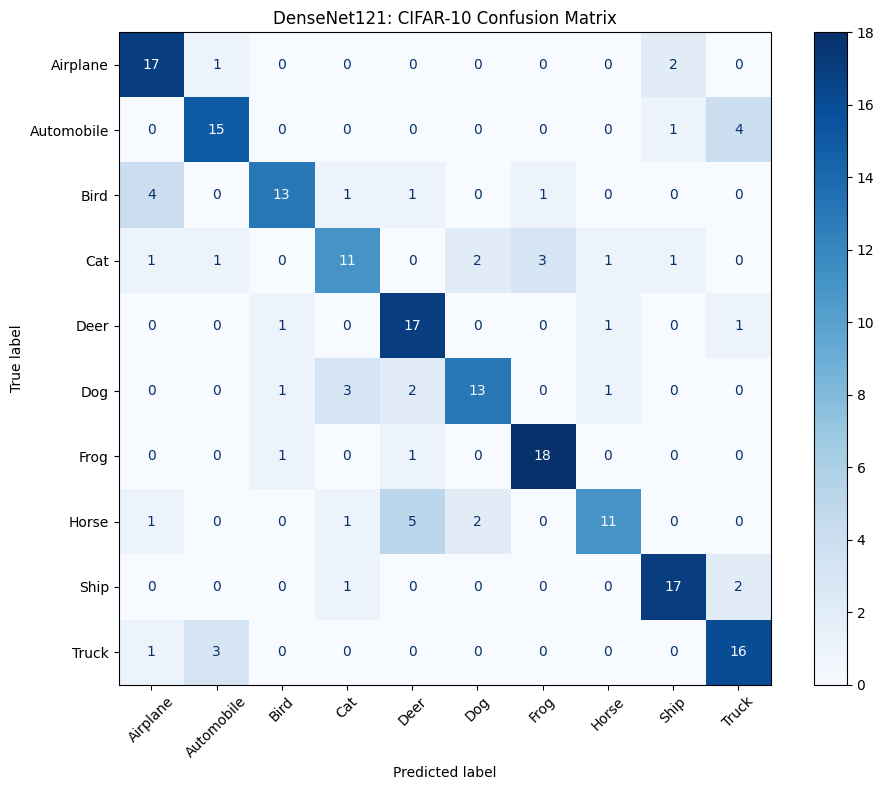

In [ ]:
for architecture in architecture_names:

    print("\n" + "=" * 60)
    print("Classification Report:", architecture)
    print("=" * 60)

    best_model = tf.keras.models.load_model(
        checkpoint_paths[architecture]
    )

    x_test = prepare_images(
        x_test_raw,
        architecture
    )

    # Predict probabilities.
    probabilities = best_model.predict(
        x_test,
        verbose=0
    )

    # Select class with highest probability.
    y_pred = np.argmax(probabilities, axis=1)

    # Classification report.
    print(classification_report(
        y_test,
        y_pred,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    ))

    # Confusion matrix.
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=list(range(10))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(10, 8))

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d"
    )

    plt.title(architecture + ": CIFAR-10 Confusion Matrix")
    plt.tight_layout()
    plt.show()

    del best_model, x_test
    tf.keras.backend.clear_session()

###my notes:
* Generates predictions for all four architectures.
* Calculates precision, recall and F1-score.
* Displays a separate confusion matrix for each model.
* Helps identify which CIFAR-10 classes are being misclassified.

Activity 9 – Display predicted test images


Predictions using: VGG16


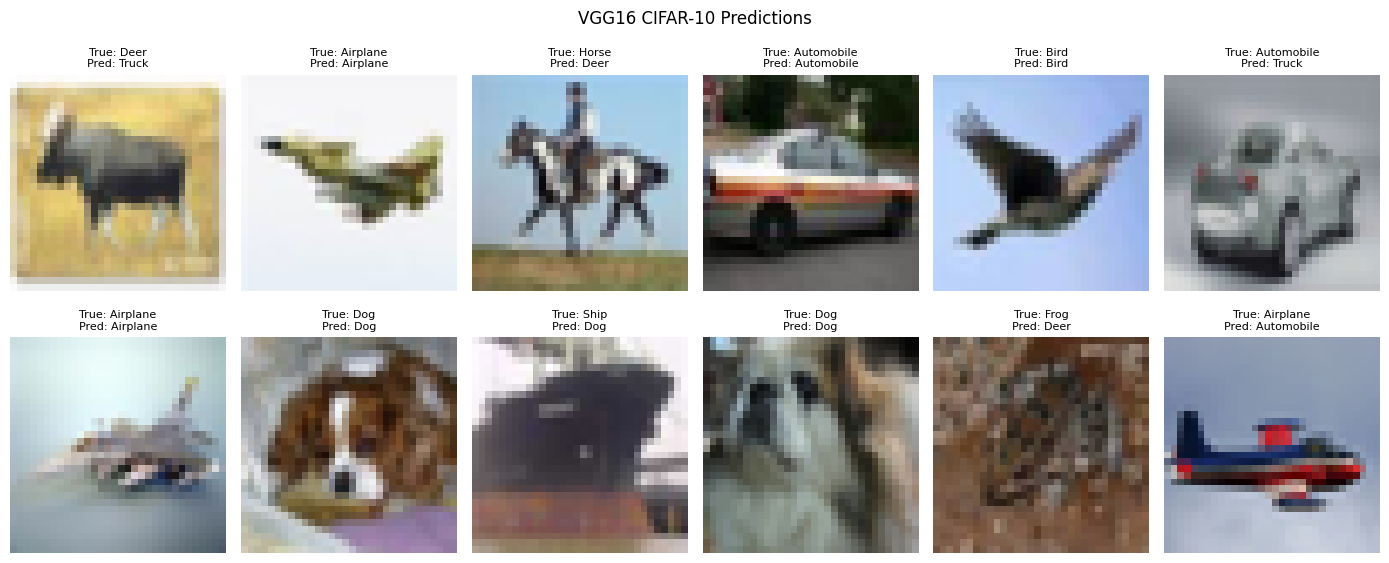


Predictions using: ResNet50


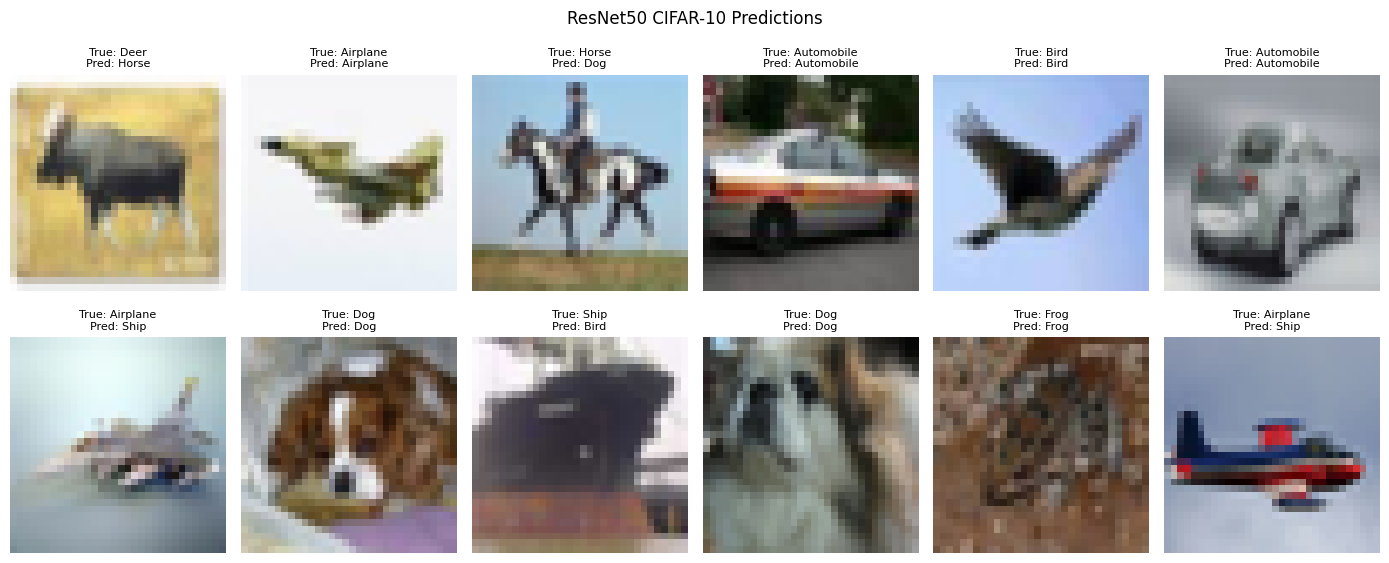


Predictions using: MobileNetV2


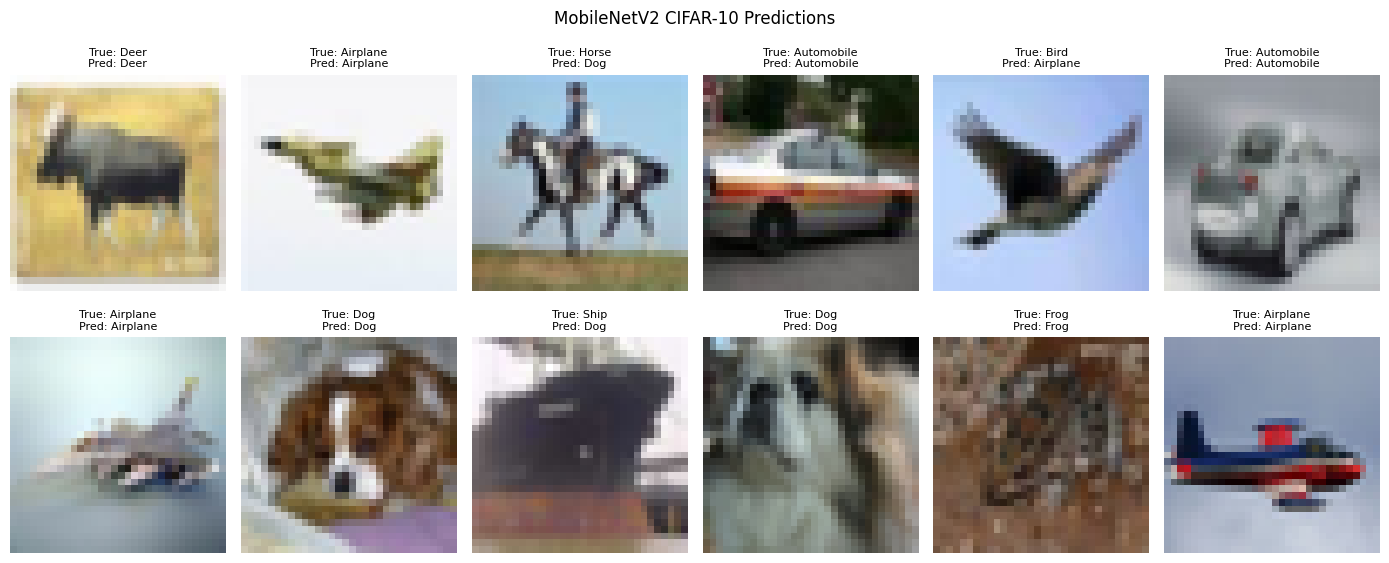


Predictions using: DenseNet121


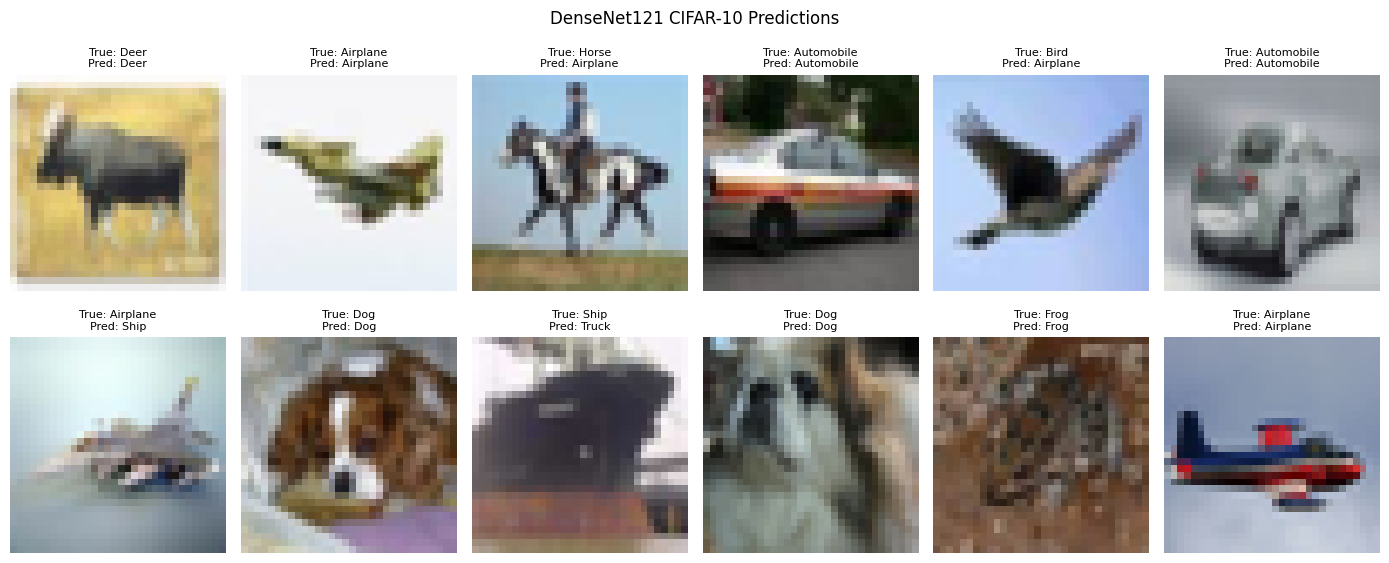

In [ ]:
for architecture in architecture_names:

    print("\nPredictions using:", architecture)

    best_model = tf.keras.models.load_model(
        checkpoint_paths[architecture]
    )

    x_test = prepare_images(
        x_test_raw,
        architecture
    )

    probabilities = best_model.predict(
        x_test,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Display first 12 test images.
    indices = np.arange(min(12, len(y_test)))

    fig, axes = plt.subplots(
        2, 6,
        figsize=(14, 6)
    )

    for ax, idx in zip(axes.flat, indices):

        ax.imshow(x_test_raw[idx])

        true_label = class_names[y_test[idx]]
        predicted_label = class_names[predictions[idx]]

        ax.set_title(
            f"True: {true_label}\nPred: {predicted_label}",
            fontsize=8
        )

        ax.axis("off")

    plt.suptitle(architecture + " CIFAR-10 Predictions")
    plt.tight_layout()
    plt.show()

    del best_model, x_test
    tf.keras.backend.clear_session()

###my notes:
* Loads each trained CNN model.
* Predicts labels for test images.
* Displays 12 test images for each architecture.
* Shows the actual and predicted class names.
* Makes it easier to visually inspect model predictions.

Activity 10 – Fine-tune the four pretrained architectures

In [ ]:
fine_tune_histories = {}
fine_tune_checkpoint_paths = {}

# Number of layers to unfreeze for each architecture.
unfreeze_layers = {
    "VGG16": 4,
    "ResNet50": 20,
    "MobileNetV2": 20,
    "DenseNet121": 20
}

for architecture in architecture_names:

    print("\n" + "=" * 60)
    print("Fine-tuning:", architecture)
    print("=" * 60)

    tf.keras.backend.clear_session()

    # Load the best model from transfer learning.
    fine_tune_model = tf.keras.models.load_model(
        checkpoint_paths[architecture]
    )

    # Get the pretrained backbone.
    backbone = fine_tune_model.get_layer(
        architecture.lower()
        if architecture != "MobileNetV2"
        else "mobilenetv2_1.00_96"
    )

    # Make backbone trainable.
    backbone.trainable = True

    # Freeze earlier layers.
    number_of_layers = unfreeze_layers[architecture]

    for layer in backbone.layers[:-number_of_layers]:
        layer.trainable = False

    # Keep Batch Normalization layers frozen.
    for layer in backbone.layers:

        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        ):
            layer.trainable = False

    print("Total backbone layers:", len(backbone.layers))

    print(
        "Trainable backbone layers:",
        sum(layer.trainable for layer in backbone.layers)
    )

    print(
        "Trainable parameters:",
        sum(
            np.prod(v.shape)
            for v in fine_tune_model.trainable_variables
        )
    )

    # Recompile with a smaller learning rate.
    fine_tune_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-5
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Prepare training and validation data.
    x_train = prepare_images(
        x_train_raw,
        architecture
    )

    x_val = prepare_images(
        x_val_raw,
        architecture
    )

    train_generator = create_train_generator(
        x_train,
        y_train
    )

    # Save best fine-tuned model.
    fine_tune_checkpoint_path = (
        "best_" + architecture.lower() + "_cifar10_finetuned.keras"
    )

    fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=fine_tune_checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    )

    # Adaptive learning rate.
    fine_tune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )

    fine_tune_early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    # Fine-tune the model.
    fine_tune_history = fine_tune_model.fit(
        train_generator,
        validation_data=(x_val, y_val),
        epochs=8,
        callbacks=[
            fine_tune_checkpoint,
            fine_tune_reduce_lr,
            fine_tune_early_stop
        ],
        verbose=1
    )

    fine_tune_histories[architecture] = fine_tune_history.history

    fine_tune_checkpoint_paths[architecture] = (
        fine_tune_checkpoint_path
    )

    print(
        "Fine-tuned checkpoint saved:",
        fine_tune_checkpoint_path
    )

    del fine_tune_model, train_generator, x_train, x_val
    tf.keras.backend.clear_session()


Fine-tuning: VGG16
Total backbone layers: 19
Trainable backbone layers: 4
Trainable parameters: 7084554
Epoch 1/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.6644 - loss: 1.6459
Epoch 1: val_loss improved from None to 1.62626, saving model to best_vgg16_cifar10_finetuned.keras

Epoch 1: finished saving model to best_vgg16_cifar10_finetuned.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 204ms/step - accuracy: 0.6475 - loss: 1.7054 - val_accuracy: 0.6500 - val_loss: 1.6263 - learning_rate: 1.0000e-05
Epoch 2/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.7118 - loss: 1.0314
Epoch 2: val_loss improved from 1.62626 to 1.47022, saving model to best_vgg16_cifar10_finetuned.keras

Epoch 2: finished saving model to best_vgg16_cifar10_finetuned.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step - accuracy: 0.7050 - loss: 1.1020 - val_accuracy: 0.6650 - val_loss: 1.4702 - learning_rate: 1.0000e-05
Epoch 3/8
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.7454 - loss: 0.8399
Epoch 3: 

### mynotes:
* Loads the best transfer-learning checkpoint.
* Unfreezes the final layers of each CNN.
* Keeps earlier layers frozen.
* Keeps Batch Normalization layers frozen.
* Uses a smaller learning rate of 1e-5.
* Applies adaptive learning rate using ReduceLROnPlateau.
* Uses early stopping and model checkpointing.
* Fine-tunes each architecture for a maximum of 8 epochs.

Activity 11 – Evaluate fine-tuned models


Evaluating fine-tuned: VGG16
Test loss: 1.6355
Test accuracy: 0.630 (63.00%)

Classification Report:

              precision    recall  f1-score   support

    Airplane       0.70      0.70      0.70        20
  Automobile       0.70      0.70      0.70        20
        Bird       0.48      0.50      0.49        20
         Cat       0.77      0.50      0.61        20
        Deer       0.54      0.65      0.59        20
         Dog       0.43      0.45      0.44        20
        Frog       0.72      0.65      0.68        20
       Horse       0.61      0.70      0.65        20
        Ship       0.70      0.70      0.70        20
       Truck       0.75      0.75      0.75        20

    accuracy                           0.63       200
   macro avg       0.64      0.63      0.63       200
weighted avg       0.64      0.63      0.63       200



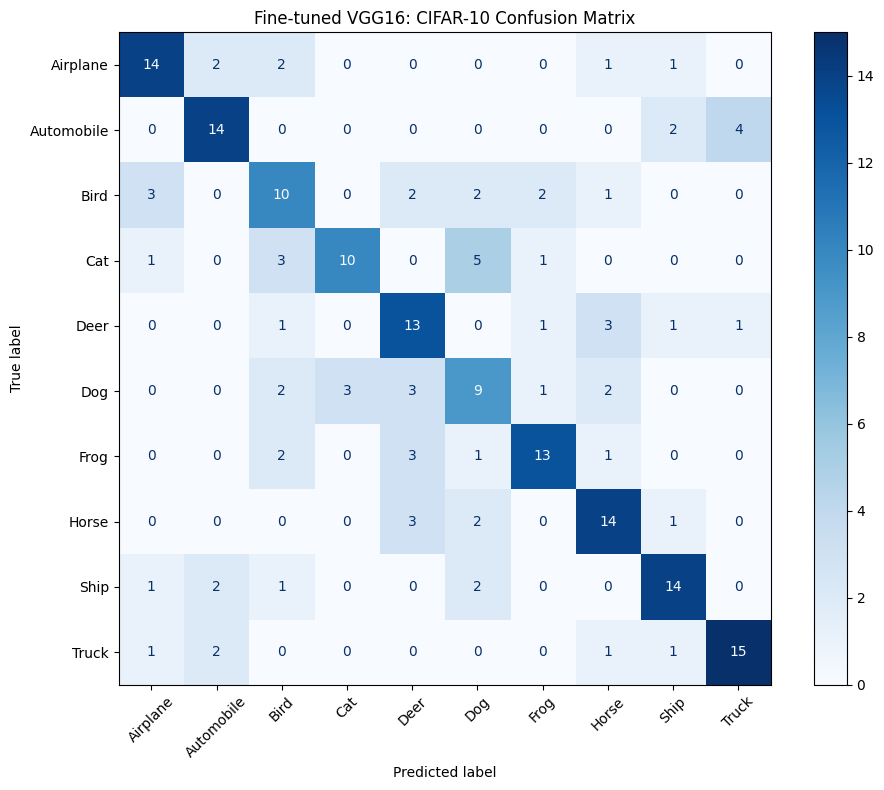


Evaluating fine-tuned: ResNet50
Test loss: 0.8009
Test accuracy: 0.760 (76.00%)

Classification Report:

              precision    recall  f1-score   support

    Airplane       0.76      0.80      0.78        20
  Automobile       0.89      0.85      0.87        20
        Bird       0.71      0.60      0.65        20
         Cat       0.80      0.60      0.69        20
        Deer       0.70      0.70      0.70        20
         Dog       0.57      0.65      0.60        20
        Frog       0.83      0.95      0.88        20
       Horse       0.68      0.65      0.67        20
        Ship       0.81      0.85      0.83        20
       Truck       0.86      0.95      0.90        20

    accuracy                           0.76       200
   macro avg       0.76      0.76      0.76       200
weighted avg       0.76      0.76      0.76       200



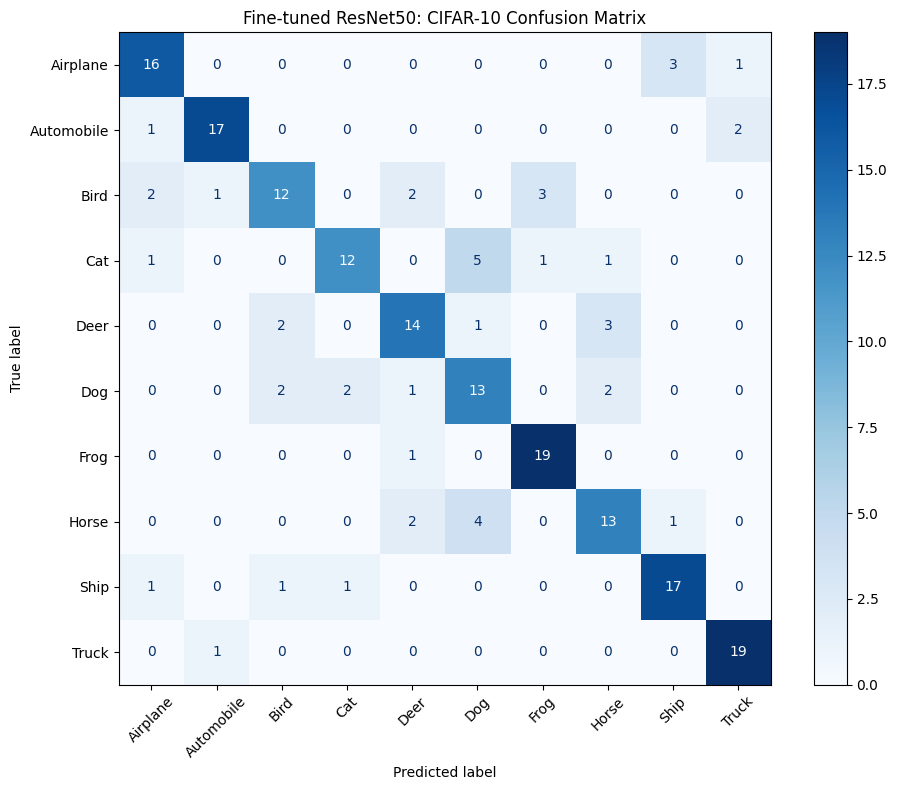


Evaluating fine-tuned: MobileNetV2
Test loss: 0.6737
Test accuracy: 0.765 (76.50%)

Classification Report:

              precision    recall  f1-score   support

    Airplane       0.74      0.70      0.72        20
  Automobile       0.90      0.90      0.90        20
        Bird       0.67      0.70      0.68        20
         Cat       0.65      0.55      0.59        20
        Deer       0.93      0.65      0.76        20
         Dog       0.74      0.70      0.72        20
        Frog       0.86      0.90      0.88        20
       Horse       0.70      0.80      0.74        20
        Ship       0.71      0.85      0.77        20
       Truck       0.82      0.90      0.86        20

    accuracy                           0.77       200
   macro avg       0.77      0.77      0.76       200
weighted avg       0.77      0.77      0.76       200



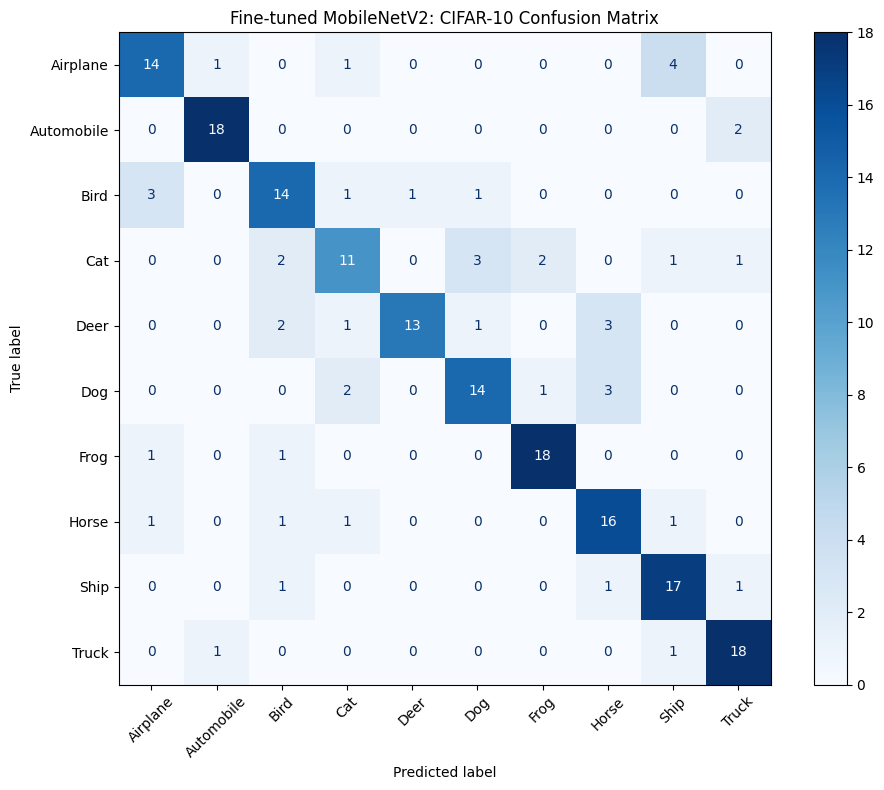


Evaluating fine-tuned: DenseNet121
Test loss: 0.7389
Test accuracy: 0.755 (75.50%)

Classification Report:

              precision    recall  f1-score   support

    Airplane       0.74      0.85      0.79        20
  Automobile       0.79      0.75      0.77        20
        Bird       0.81      0.65      0.72        20
         Cat       0.67      0.50      0.57        20
        Deer       0.70      0.80      0.74        20
         Dog       0.81      0.65      0.72        20
        Frog       0.82      0.90      0.86        20
       Horse       0.76      0.80      0.78        20
        Ship       0.77      0.85      0.81        20
       Truck       0.70      0.80      0.74        20

    accuracy                           0.76       200
   macro avg       0.76      0.76      0.75       200
weighted avg       0.76      0.76      0.75       200



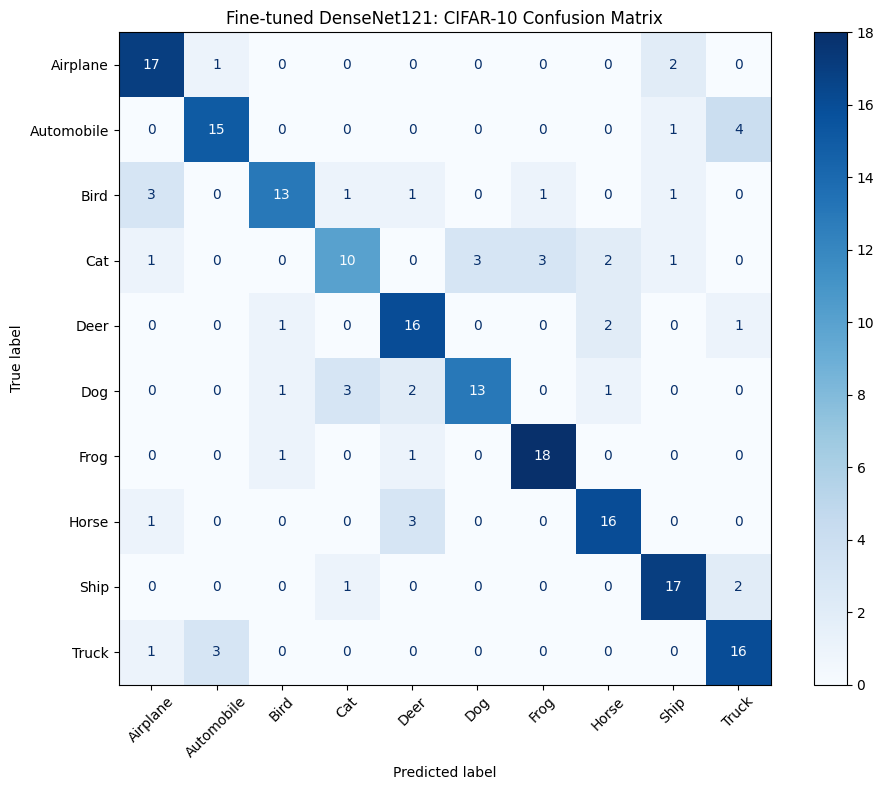

In [ ]:
fine_tuned_results = {}

for architecture in architecture_names:

    print("\nEvaluating fine-tuned:", architecture)

    # Load best fine-tuned model.
    fine_tuned_model = tf.keras.models.load_model(
        fine_tune_checkpoint_paths[architecture]
    )

    # Prepare test images.
    x_test = prepare_images(
        x_test_raw,
        architecture
    )

    # Evaluate.
    test_loss, test_accuracy = fine_tuned_model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    fine_tuned_results[architecture] = {
        "loss": test_loss,
        "accuracy": test_accuracy
    }

    print("Test loss:", round(test_loss, 4))

    print(
        "Test accuracy:",
        f"{test_accuracy:.3f} ({test_accuracy * 100:.2f}%)"
    )

    # Generate predictions.
    probabilities = fine_tuned_model.predict(
        x_test,
        verbose=0
    )

    fine_tuned_predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Classification report.
    print("\nClassification Report:\n")

    print(classification_report(
        y_test,
        fine_tuned_predictions,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    ))

    # Confusion matrix.
    cm = confusion_matrix(
        y_test,
        fine_tuned_predictions,
        labels=list(range(10))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(10, 8))

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d"
    )

    plt.title(
        "Fine-tuned " + architecture + ": CIFAR-10 Confusion Matrix"
    )

    plt.tight_layout()
    plt.show()

    del fine_tuned_model, x_test
    tf.keras.backend.clear_session()

###my notes:
* Loads the best fine-tuned model.
* Evaluates test loss and test accuracy.
* Generates precision, recall and F1-score.
* Displays a confusion matrix for every fine-tuned architecture.
* Stores the final results for comparison.

Activity 12 – Compare all four CNN architectures.

CIFAR-10: CNN ARCHITECTURE PERFORMANCE COMPARISON
Architecture   Before FT         After FT          Improvement    
---------------------------------------------------------------------------
VGG16          57.00             63.00             +6.00%
ResNet50       76.50             76.00             -0.50%
MobileNetV2    76.00             76.50             +0.50%
DenseNet121    74.00             75.50             +1.50%


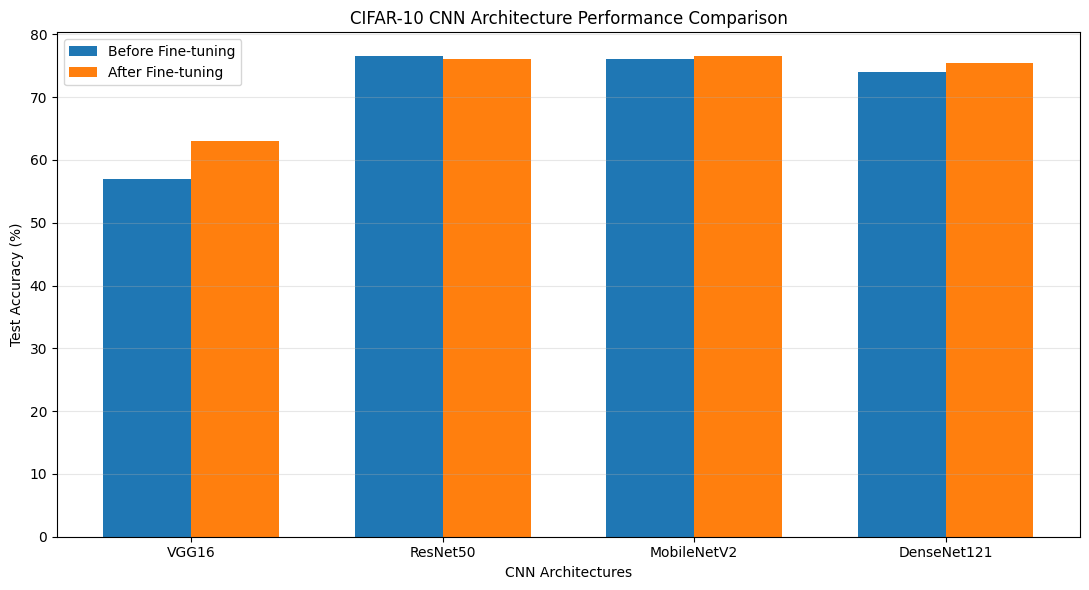


FINAL MODEL PERFORMANCE

Architecture: VGG16
Before fine-tuning: 57.0 %
After fine-tuning: 63.0 %
Final test loss: 1.6355

Architecture: ResNet50
Before fine-tuning: 76.5 %
After fine-tuning: 76.0 %
Final test loss: 0.8009

Architecture: MobileNetV2
Before fine-tuning: 76.0 %
After fine-tuning: 76.5 %
Final test loss: 0.6737

Architecture: DenseNet121
Before fine-tuning: 74.0 %
After fine-tuning: 75.5 %
Final test loss: 0.7389


In [ ]:
# Compare transfer learning and fine-tuning results.

print("=" * 75)
print("CIFAR-10: CNN ARCHITECTURE PERFORMANCE COMPARISON")
print("=" * 75)

print(
    f"{'Architecture':<15}"
    f"{'Before FT':<18}"
    f"{'After FT':<18}"
    f"{'Improvement':<15}"
)

print("-" * 75)

for architecture in architecture_names:

    before = baseline_results[architecture]["accuracy"] * 100

    after = fine_tuned_results[architecture]["accuracy"] * 100

    improvement = after - before

    print(
        f"{architecture:<15}"
        f"{before:<18.2f}"
        f"{after:<18.2f}"
        f"{improvement:+.2f}%"
    )


# Plot comparison of test accuracy.

before_accuracies = [
    baseline_results[name]["accuracy"] * 100
    for name in architecture_names
]

after_accuracies = [
    fine_tuned_results[name]["accuracy"] * 100
    for name in architecture_names
]

x = np.arange(len(architecture_names))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    before_accuracies,
    width,
    label="Before Fine-tuning"
)

plt.bar(
    x + width / 2,
    after_accuracies,
    width,
    label="After Fine-tuning"
)

plt.xlabel("CNN Architectures")
plt.ylabel("Test Accuracy (%)")

plt.title("CIFAR-10 CNN Architecture Performance Comparison")

plt.xticks(x, architecture_names)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Display final performance table.

print("\nFINAL MODEL PERFORMANCE")

for architecture in architecture_names:

    print("\nArchitecture:", architecture)

    print(
        "Before fine-tuning:",
        round(
            baseline_results[architecture]["accuracy"] * 100,
            2
        ),
        "%"
    )

    print(
        "After fine-tuning:",
        round(
            fine_tuned_results[architecture]["accuracy"] * 100,
            2
        ),
        "%"
    )

    print(
        "Final test loss:",
        round(fine_tuned_results[architecture]["loss"], 4)
    )

###my note:
* Compares all four CNN architectures.
* Shows accuracy before fine-tuning.
* Shows accuracy after fine-tuning.
* Calculates the accuracy improvement or decrease.
* Displays a bar chart for visual comparison.
* Prints the final test loss and accuracy for every architecture.

Activity 13 – Final performance comparison

FINAL PERFORMANCE COMPARISON OF FOUR CNN ARCHITECTURES


,Architecture,Test Loss,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Before Fine-tuning (%),After Fine-tuning (%),Improvement (%)
0,VGG16,1.6355,63.0,63.97,63.0,63.09,57.0,63.0,6.0
1,ResNet50,0.8009,76.0,76.11,76.0,75.76,76.5,76.0,-0.5
2,MobileNetV2,0.6737,76.5,76.95,76.5,76.30,76.0,76.5,0.5
3,DenseNet121,0.7389,75.5,75.64,75.5,75.11,74.0,75.5,1.5



Highest Test Accuracy:
Architecture              MobileNetV2
Test Loss                      0.6737
Accuracy (%)                     76.5
Precision (%)                   76.95
Recall (%)                       76.5
F1-Score (%)                     76.3
Before Fine-tuning (%)           76.0
After Fine-tuning (%)            76.5
Improvement (%)                   0.5
Name: 2, dtype: object


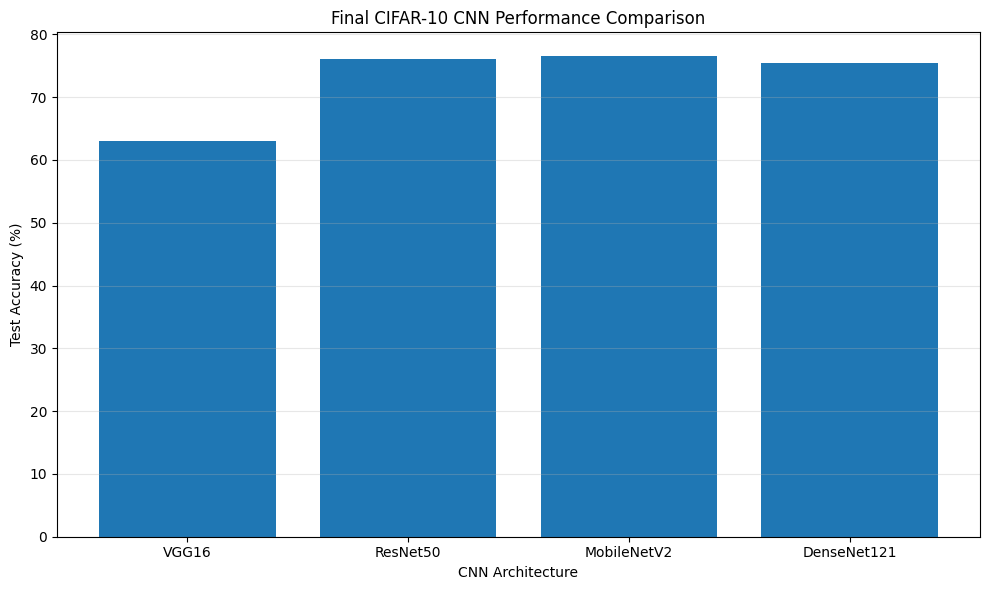

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

final_results = []

for architecture in architecture_names:

    # Load best fine-tuned model
    model = tf.keras.models.load_model(
        fine_tune_checkpoint_paths[architecture]
    )

    # Prepare test data
    x_test = prepare_images(
        x_test_raw,
        architecture
    )

    # Evaluate model
    test_loss, test_accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    # Generate predictions
    probabilities = model.predict(
        x_test,
        verbose=0
    )

    y_pred = np.argmax(probabilities, axis=1)

    # Calculate evaluation metrics
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    # Calculate improvement after fine-tuning
    before_accuracy = baseline_results[architecture]["accuracy"] * 100
    after_accuracy = test_accuracy * 100

    improvement = after_accuracy - before_accuracy

    final_results.append({
        "Architecture": architecture,
        "Test Loss": round(test_loss, 4),
        "Accuracy (%)": round(after_accuracy, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2),
        "Before Fine-tuning (%)": round(before_accuracy, 2),
        "After Fine-tuning (%)": round(after_accuracy, 2),
        "Improvement (%)": round(improvement, 2)
    })

    del model, x_test
    tf.keras.backend.clear_session()


# Create final comparison table
final_df = pd.DataFrame(final_results)

print("FINAL PERFORMANCE COMPARISON OF FOUR CNN ARCHITECTURES")

display(final_df)

# Identify architecture with highest test accuracy
best_index = final_df["Accuracy (%)"].idxmax()

print("\nHighest Test Accuracy:")
print(final_df.loc[best_index])

# Plot final accuracy comparison
plt.figure(figsize=(10, 6))

plt.bar(
    final_df["Architecture"],
    final_df["Accuracy (%)"]
)

plt.xlabel("CNN Architecture")
plt.ylabel("Test Accuracy (%)")
plt.title("Final CIFAR-10 CNN Performance Comparison")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

###my notes:
* Calculates final test loss and accuracy.
* Calculates weighted precision, recall and F1-score.
* Compares accuracy before and after fine-tuning.
* Calculates the improvement in accuracy.
* Creates a final performance comparison table.
* Identifies the architecture with the highest test accuracy.
* Displays a final accuracy comparison graph.